In [ ]:
!pip -q install huggingface_hub datasets pyarrow scikit-learn matplotlib

## 1. Pick models
The list mixes weak and strong models. Any that are missing on the leaderboard are skipped automatically.

In [ ]:
CANDIDATE_MODELS = [
    "meta-llama__Llama-2-7b-hf", "meta-llama__Llama-2-13b-hf", "meta-llama__Llama-2-70b-hf",
    "huggyllama__llama-7b", "huggyllama__llama-65b",
    "mistralai__Mistral-7B-v0.1", "mistralai__Mixtral-8x7B-v0.1",
    "tiiuae__falcon-7b", "tiiuae__falcon-40b", "01-ai__Yi-34B", "Qwen__Qwen-14B",
    "google__gemma-7b", "microsoft__phi-2", "EleutherAI__gpt-j-6b", "EleutherAI__pythia-12b",
    "mosaicml__mpt-7b", "facebook__opt-13b", "bigscience__bloom-7b1",
    "stabilityai__stablelm-3b-4e1t", "openlm-research__open_llama_7b",
]

## 2. Find each model's latest MMLU files

In [ ]:
import re, json, hashlib, os
import numpy as np, pandas as pd
from huggingface_hub import HfApi, hf_hub_download
from concurrent.futures import ThreadPoolExecutor

api = HfApi()
SUBJ_RE = re.compile(r"hendrycksTest-([a-z_]+)\|5")

def latest_mmlu_files(repo):
    """One parquet per MMLU subject; if a model was run more than once, keep the latest run."""
    by_subj = {}
    for f in api.list_repo_files(repo, repo_type="dataset"):
        if not f.endswith(".parquet"):
            continue
        m = SUBJ_RE.search(f)
        if m and (m.group(1) not in by_subj or f > by_subj[m.group(1)]):
            by_subj[m.group(1)] = f
    return by_subj

def check(name):
    repo = f"open-llm-leaderboard-old/details_{name}"
    try:
        fs = latest_mmlu_files(repo)
    except Exception as e:
        return name, None, f"skip ({type(e).__name__})"
    if len(fs) < 57:
        return name, None, f"skip (only {len(fs)} subjects)"
    return name, (repo, fs), "ok"

models = {}
with ThreadPoolExecutor(8) as ex:
    for name, val, msg in ex.map(check, CANDIDATE_MODELS):
        print(f"{msg:28s} {name}")
        if val:
            models[name] = val
print(f"\n{len(models)} models usable")

ok                           meta-llama__Llama-2-7b-hf
ok                           meta-llama__Llama-2-13b-hf
ok                           meta-llama__Llama-2-70b-hf
ok                           huggyllama__llama-7b
ok                           huggyllama__llama-65b
ok                           mistralai__Mistral-7B-v0.1
ok                           mistralai__Mixtral-8x7B-v0.1
ok                           tiiuae__falcon-7b
ok                           tiiuae__falcon-40b
ok                           01-ai__Yi-34B
ok                           Qwen__Qwen-14B
ok                           google__gemma-7b
ok                           microsoft__phi-2
ok                           EleutherAI__gpt-j-6b
ok                           EleutherAI__pythia-12b
ok                           mosaicml__mpt-7b
ok                           facebook__opt-13b
ok                           bigscience__bloom-7b1
ok                           stabilityai__stablelm-3b-4e1t
ok                           openlm-res

## 3. Peek at one file (for debugging only)


In [ ]:
def dl(repo, f):
    return hf_hub_download(repo, f, repo_type="dataset")

n0, (r0, fs0) = next(iter(models.items()))
df0 = pd.read_parquet(dl(r0, fs0["abstract_algebra"]))
print("columns:", df0.columns.tolist())
row0 = df0.iloc[0].to_dict()
for k, v in row0.items():
    print(f"--- {k}: {str(v)[:300]}")

columns: ['acc', 'acc_norm', 'choices', 'cont_tokens', 'example', 'full_prompt', 'gold', 'hashes', 'input_tokens', 'instruction', 'num_asked_few_shots', 'num_effective_few_shots', 'padded', 'predictions', 'query', 'truncated']
--- acc: 0.0
--- acc_norm: 0.0
--- choices: ['A' 'B' 'C' 'D']
--- cont_tokens: [array([319]) array([350]) array([315]) array([360])]
--- example: Statement 1 | Some abelian group of order 45 has a subgroup of order 10. Statement 2 | A subgroup H of a group G is a normal subgroup if and only if thenumber of left cosets of H is equal to the number of right cosets of H.
A. True, True
B. False, False
C. True, False
D. False, True
Answer:
--- full_prompt: The following are multiple choice questions (with answers) about abstract algebra.

Find all c in Z_3 such that Z_3[x]/(x^2 + c) is a field.
A. 0
B. 1
C. 2
D. 3
Answer: B

Statement 1 | If aH is an element of a factor group, then |aH| divides |a|. Statement 2 | If H and K are subgroups of G then HK 
--- gold: 1
--- h

## 4. Download and parse all models

In [ ]:
LETTERS = "ABCD"

def to_text(r):
    for c in ["example", "query", "full_prompt", "question"]:
        v = r.get(c)
        if isinstance(v, str) and v.strip():
            return v
    return ""

def to_gold(r):
    for c in ["gold_index", "gold"]:
        if c in r:
            g = r[c]
            if isinstance(g, (list, tuple, np.ndarray)):
                g = g[0] if len(g) else None
            if isinstance(g, str) and g.strip() in LETTERS:
                return LETTERS.index(g.strip())
            try:
                return int(g)
            except (TypeError, ValueError):
                pass
    return None

def to_lls(r):
    p = r.get("predictions")
    if p is None:
        return None
    out = []
    for x in list(p):
        if isinstance(x, (list, tuple, np.ndarray)):
            x = x[0]
        out.append(float(x))
    return np.array(out) if len(out) == 4 else None

def norm(t):
    return re.sub(r"\s+", " ", str(t).lower()).strip()

def question_key(text):
    """Question text + first option, so generic stems like 'Which of the following is true?' don't collide."""
    t = text.split("\n\n")[-1]              # last block of a 5-shot prompt = the real question
    parts = re.split(r"\nA\.\s*", t, maxsplit=1)
    q = re.sub(r"^Question:\s*", "", parts[0].strip())
    opt_a = re.split(r"\nB\.", parts[1])[0] if len(parts) > 1 else ""
    return norm(q)[:150] + " || " + norm(opt_a)[:60]

def load_model(name):
    repo, fs = models[name]
    rows = []
    for subj, f in fs.items():
        df = pd.read_parquet(dl(repo, f))
        for i, r in enumerate(df.to_dict("records")):
            lls, g = to_lls(r), to_gold(r)
            if lls is not None and g is not None:
                rows.append((subj, i, question_key(to_text(r)), g, lls))
    return name, rows

with ThreadPoolExecutor(6) as ex:
    results = dict(ex.map(load_model, list(models)))
for n, rows in results.items():
    print(f"{len(rows):6d} questions  {n}")

   570 questions  meta-llama__Llama-2-7b-hf
 14042 questions  meta-llama__Llama-2-13b-hf
 14042 questions  meta-llama__Llama-2-70b-hf
     0 questions  huggyllama__llama-7b
 14042 questions  huggyllama__llama-65b
 14042 questions  mistralai__Mistral-7B-v0.1
     0 questions  mistralai__Mixtral-8x7B-v0.1
 14042 questions  tiiuae__falcon-7b
 14042 questions  tiiuae__falcon-40b
     0 questions  01-ai__Yi-34B
 14042 questions  Qwen__Qwen-14B
     0 questions  google__gemma-7b
     0 questions  microsoft__phi-2
 14042 questions  EleutherAI__gpt-j-6b
 14042 questions  EleutherAI__pythia-12b
 14042 questions  mosaicml__mpt-7b
 14042 questions  facebook__opt-13b
 14042 questions  bigscience__bloom-7b1
 14042 questions  stabilityai__stablelm-3b-4e1t
 14042 questions  openlm-research__open_llama_7b


## 5. Build the models-by-questions matrix and the scores

In [ ]:
names = [n for n in results if len(results[n]) > 10000]
keys = sorted({(s, i) for n in names for (s, i, _, _, _) in results[n]})
idx = {k: j for j, k in enumerate(keys)}
M, Q = len(names), len(keys)
P = np.full((M, Q, 4), np.nan); gold = np.full(Q, -1); qtext = [""] * Q
for mi, n in enumerate(names):
    for s, i, qk, g, lls in results[n]:
        j = idx[(s, i)]
        e = np.exp(lls - lls.max()); P[mi, j] = e / e.sum()   # softmax over options A-D
        gold[j] = g; qtext[j] = qtext[j] or qk

keep = ~np.isnan(P).any(axis=(0, 2)) & (gold >= 0)
P, gold = P[:, keep], gold[keep]
keys = [k for k, ok in zip(keys, keep) if ok]; qtext = [t for t, ok in zip(qtext, keep) if ok]
Q = len(keys)

pg = P[:, np.arange(Q), gold]                  # prob. each model gives the official answer
choice = P.argmax(axis=2)
correct = choice == gold[None, :]
model_acc = correct.mean(axis=1)

conf, var, acc_q = pg.mean(0), pg.std(0), correct.mean(0)
top = np.argsort(model_acc)[-max(2, int(round(0.2 * M))):]
top_conf = pg[top].mean(0)
a = model_acc - model_acc.mean(); pc = pg - pg.mean(0)
align = (a[:, None] * pc).sum(0) / (np.sqrt((a ** 2).sum()) * np.sqrt((pc ** 2).sum(0)) + 1e-12)

votes = np.stack([(choice == k).sum(0) for k in range(4)], 1)
vf = votes / M
entropy = -np.where(vf > 0, vf * np.log(np.where(vf > 0, vf, 1)), 0).sum(1)
plural = votes.argmax(1)
majority_against = (plural != gold) * vf.max(1)
tv = np.stack([(choice[top] == k).sum(0) for k in range(4)], 1).astype(float)
tv_alt = tv.copy(); tv_alt[np.arange(Q), gold] = -1
cons_alt = tv_alt.argmax(1); cons_share = tv[np.arange(Q), cons_alt] / len(top)

print(f"{M} models x {Q} questions with complete data")
print("model accuracy range:", model_acc.min().round(3), "-", model_acc.max().round(3))

14 models x 14042 questions with complete data
model accuracy range: 0.25 - 0.692


## 6. Match to MMLU-Redux 2.0

In [ ]:
from datasets import load_dataset
red, n_red_rows = {}, 0
for s in sorted({k[0] for k in keys}):
    try:
        d = load_dataset("edinburgh-dawg/mmlu-redux-2.0", s, split="test")
    except Exception as e:
        print("redux missing:", s, type(e).__name__); continue
    for r in d:
        n_red_rows += 1
        rk = (s, norm(r["question"])[:150] + " || " + norm(r["choices"][0])[:60])
        red[rk] = (r["error_type"], r.get("correct_answer"))

# exact match first: each Redux row claims at most one leaderboard question
import difflib
key_idx = {}
for j, (k, t) in enumerate(zip(keys, qtext)):
    key_idx.setdefault((k[0], t), []).append(j)
labels, used, how = [None] * len(keys), set(), [""] * len(keys)
for rk, val in red.items():
    js = [j for j in key_idx.get(rk, []) if labels[j] is None]
    if js:
        labels[js[0]] = val; used.add(rk); how[js[0]] = "exact"
n_exact = len(used)

# fuzzy fallback for the rest (same subject, text similarity >= 0.9)
free = {}
for j, k in enumerate(keys):
    if labels[j] is None:
        free.setdefault(k[0], []).append(j)
for rk, val in red.items():
    if rk in used:
        continue
    best, bj = 0.0, None
    for j in free.get(rk[0], []):
        if labels[j] is None:
            r = difflib.SequenceMatcher(None, rk[1], qtext[j]).ratio()
            if r > best:
                best, bj = r, j
    if bj is not None and best >= 0.9:
        labels[bj] = val; used.add(rk); how[bj] = "fuzzy"
matched = len(used)
unmatched = [rk for rk in red if rk not in used]
print(f"MMLU-Redux rows: {n_red_rows}; unique keys: {len(red)}; exact: {n_exact}; "
      f"after fuzzy: {matched} ({matched/n_red_rows:.1%})")
for rk in unmatched[:3]:
    print("  still unmatched:", rk[0], "|", rk[1][:110])

MMLU-Redux rows: 5700; unique keys: 5557; exact: 5500; after fuzzy: 5505 (96.6%)
  still unmatched: college_medicine | sauna use, sometimes referred to as "sauna bathing," is characterized by short-term passive exposure to extrem
  still unmatched: college_medicine | what is the most likely outcome of this modification? ﻿ an rna strand that normally produces a transmembrane p
  still unmatched: college_medicine | using this formula, if a reaction was provided with 84g of ethane and unlimited oxygen, how many grams of carb


## 7. First detection check (RQ2, preliminary)

In [ ]:
from sklearn.metrics import average_precision_score
lab = np.array([l is not None for l in labels])
etype = np.array([l[0] if l else "" for l in labels])
y_any = (etype != "ok")[lab]
y_wrong = (etype == "wrong_groundtruth")[lab]
scores = {
    "random": np.random.default_rng(0).random(Q),
    "low accuracy": 1 - acc_q,
    "majority vote vs key": majority_against,
    "low confidence": 1 - conf,
    "low top-tier confidence": 1 - top_conf,
    "negative ability alignment": -align,
}
rows = []
for k, v in scores.items():
    rows.append((k, average_precision_score(y_any, v[lab]), average_precision_score(y_wrong, v[lab])))
ap = pd.DataFrame(rows, columns=["score", "AUPRC any error", "AUPRC wrong key"]).round(3)
print(f"base rates: any error {y_any.mean():.3f}, wrong key {y_wrong.mean():.3f}")
print(ap.to_string(index=False))

# RQ3-style check: when top models agree on another option, does it match Redux's correction?
def letter_to_idx(x):
    if x is None: return None
    x = str(x).strip()
    if x in LETTERS: return LETTERS.index(x)
    return int(x) if x.isdigit() else None
wg = [j for j in range(Q) if labels[j] and labels[j][0] == "wrong_groundtruth" and letter_to_idx(labels[j][1]) is not None]
strong = [j for j in wg if cons_share[j] >= 0.5]
hit = sum(cons_alt[j] == letter_to_idx(labels[j][1]) for j in strong)
print(f"\nwrong-key questions with a correction: {len(wg)}; with top-tier consensus >= 50%: {len(strong)}; "
      f"consensus matches Redux correction: {hit}/{len(strong)}")

base rates: any error 0.066, wrong key 0.019
                     score  AUPRC any error  AUPRC wrong key
                    random            0.074            0.023
              low accuracy            0.102            0.055
      majority vote vs key            0.100            0.052
            low confidence            0.169            0.174
   low top-tier confidence            0.209            0.260
negative ability alignment            0.196            0.217

wrong-key questions with a correction: 100; with top-tier consensus >= 50%: 77; consensus matches Redux correction: 57/77


## 8. First data map

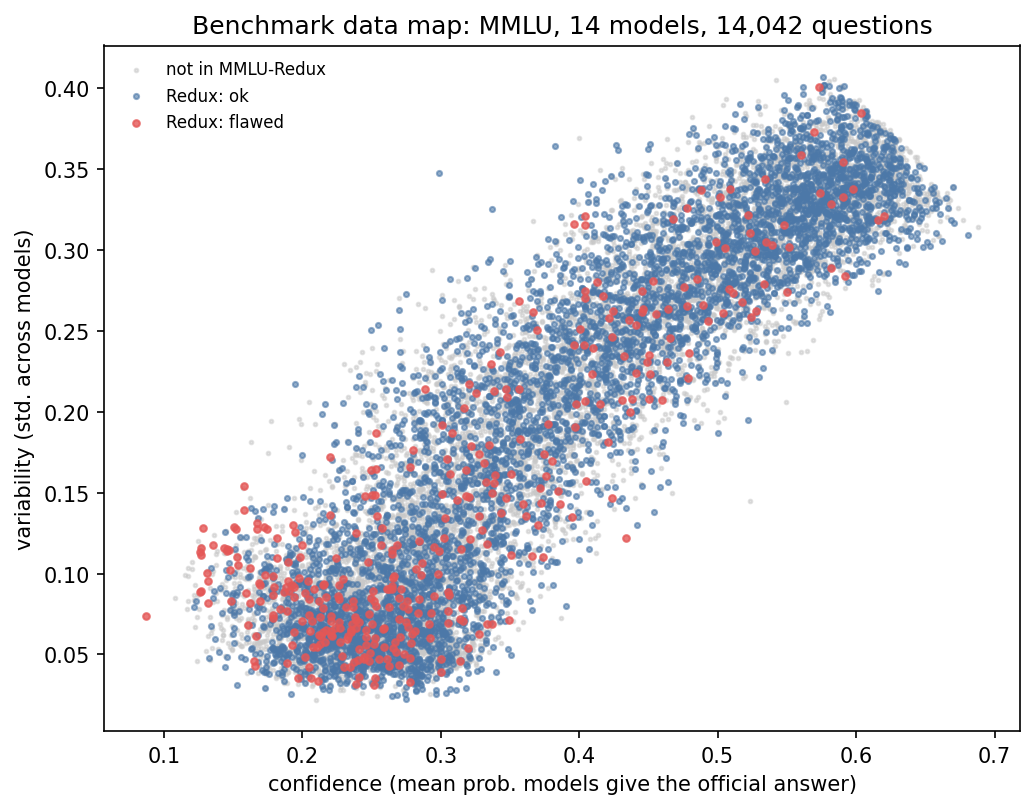

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=150)
ax.scatter(conf[~lab], var[~lab], s=3, c="#c8c8c8", alpha=0.5, label="not in MMLU-Redux", rasterized=True)
ok = lab & (etype == "ok"); bad = lab & (etype != "ok")
ax.scatter(conf[ok], var[ok], s=6, c="#4c78a8", alpha=0.6, label="Redux: ok")
ax.scatter(conf[bad], var[bad], s=10, c="#e45756", alpha=0.8, label="Redux: flawed")
ax.set_xlabel("confidence (mean prob. models give the official answer)")
ax.set_ylabel("variability (std. across models)")
ax.set_title(f"Benchmark data map: MMLU, {M} models, {Q:,} questions")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("data_map.png"); plt.show()

## 9. Save outputs for the repo (feedback point 4: cached data + checksum + harness version)

In [ ]:
out = pd.DataFrame({
    "subject": [k[0] for k in keys], "row": [k[1] for k in keys], "question_key": qtext,
    "gold": gold, "confidence": conf, "variability": var, "accuracy": acc_q,
    "top_tier_confidence": top_conf, "ability_alignment": align, "vote_entropy": entropy,
    "consensus_alt": cons_alt, "consensus_share": cons_share, "majority_against": majority_against,
    "redux_error_type": [l[0] if l else None for l in labels],
})
out.to_csv("question_scores.csv", index=False)
sha = hashlib.sha256(open("question_scores.csv", "rb").read()).hexdigest()
manifest = {
    "source": "open-llm-leaderboard-old details, lm-eval-harness hendrycksTest, 5-shot",
    "models": {n: {"accuracy": float(model_acc[i]), "files": sorted(models[n][1].values())} for i, n in enumerate(names)},
    "question_scores_sha256": sha,
}
json.dump(manifest, open("manifest.json", "w"), indent=1)
print("saved question_scores.csv, manifest.json, data_map.png")

saved question_scores.csv, manifest.json, data_map.png


## 10. SUMMARY

In [ ]:
print("===== SUMMARY =====")
print("models:", M, "| questions:", Q, "| model accuracy range:", round(model_acc.min(), 3), "-", round(model_acc.max(), 3))
print("models used:", ", ".join(names))
print(f"Redux matched: {matched}/{n_red_rows} ({matched/n_red_rows:.1%})")
print(f"base rates: any error {y_any.mean():.3f}, wrong key {y_wrong.mean():.3f}")
print(ap.to_string(index=False))
print(f"consensus vs Redux correction: {hit}/{len(strong)} (of {len(wg)} wrong-key questions)")
print("flawed vs ok, median confidence:", round(np.median(conf[bad]), 3), "vs", round(np.median(conf[ok]), 3))
print("flawed vs ok, median top-tier confidence:", round(np.median(top_conf[bad]), 3), "vs", round(np.median(top_conf[ok]), 3))
print("sha256:", sha[:16])

===== SUMMARY =====
models: 14 | questions: 14042 | model accuracy range: 0.25 - 0.692
models used: meta-llama__Llama-2-13b-hf, meta-llama__Llama-2-70b-hf, huggyllama__llama-65b, mistralai__Mistral-7B-v0.1, tiiuae__falcon-7b, tiiuae__falcon-40b, Qwen__Qwen-14B, EleutherAI__gpt-j-6b, EleutherAI__pythia-12b, mosaicml__mpt-7b, facebook__opt-13b, bigscience__bloom-7b1, stabilityai__stablelm-3b-4e1t, openlm-research__open_llama_7b
Redux matched: 5505/5700 (96.6%)
base rates: any error 0.066, wrong key 0.019
                     score  AUPRC any error  AUPRC wrong key
                    random            0.074            0.023
              low accuracy            0.102            0.055
      majority vote vs key            0.100            0.052
            low confidence            0.169            0.174
   low top-tier confidence            0.209            0.260
negative ability alignment            0.196            0.217
consensus vs Redux correction: 57/77 (of 100 wrong-key questions)

# Part 2: IRT baseline, first ranking result, JSON for D3
Run these after Part 1, in the same Colab session.

## 11. IRT baseline (2-parameter model, fitted directly with numpy)
Each model gets an ability; each question gets a difficulty and a discrimination. Low or negative discrimination (stronger models do *not* do better) is the classic sign of a bad item.

In [ ]:
def fit_2pl(Y, iters=1500, lr=0.05, reg=0.01):
    """Joint max-likelihood 2PL with Adam. Y: models x questions, 1 = correct."""
    Mm, Qq = Y.shape
    th, a, b = np.zeros(Mm), np.ones(Qq), np.zeros(Qq)
    params = [th, a, b]
    m1 = [np.zeros_like(p) for p in params]; m2 = [np.zeros_like(p) for p in params]
    for t in range(1, iters + 1):
        p = 1 / (1 + np.exp(-a[None, :] * (th[:, None] - b[None, :])))
        r = Y - p
        grads = [(r * a[None, :]).sum(1) - reg * th,
                 (r * (th[:, None] - b[None, :])).sum(0) - reg * (a - 1),
                 (-r * a[None, :]).sum(0) - reg * b]
        for i, (pp, g) in enumerate(zip(params, grads)):
            m1[i] = 0.9 * m1[i] + 0.1 * g; m2[i] = 0.999 * m2[i] + 0.001 * g * g
            pp += lr * (m1[i] / (1 - 0.9 ** t)) / (np.sqrt(m2[i] / (1 - 0.999 ** t)) + 1e-8)
        th -= th.mean()
        np.clip(a, -10, 10, out=a); np.clip(b, -10, 10, out=b)
    return th, a, b

theta, irt_a, irt_b = fit_2pl(correct.astype(float))
print("IRT ability vs accuracy correlation:", round(np.corrcoef(theta, model_acc)[0, 1], 3))

for k, v in {"IRT low discrimination": -irt_a, "IRT difficulty": irt_b}.items():
    ap.loc[len(ap)] = [k, round(average_precision_score(y_any, v[lab]), 3),
                       round(average_precision_score(y_wrong, v[lab]), 3)]
ap = ap.sort_values("AUPRC wrong key").reset_index(drop=True)
print(ap.to_string(index=False))

IRT ability vs accuracy correlation: 0.995
                     score  AUPRC any error  AUPRC wrong key
                    random            0.074            0.023
      majority vote vs key            0.100            0.052
              low accuracy            0.102            0.055
    IRT low discrimination            0.108            0.061
            IRT difficulty            0.131            0.070
            low confidence            0.169            0.174
negative ability alignment            0.196            0.217
   low top-tier confidence            0.209            0.260


## 12. Ranking impact (RQ3), with the difficulty-matched comparison the feedback asked for
We remove or fix questions, re-score every model, and count how many model pairs swap order. Then we do the same with random questions of the *same difficulty*, 1,000 times, to see if the effect is bigger than chance.

In [ ]:
from scipy.stats import kendalltau

def pair_swaps(new_acc, old_acc=model_acc):
    d_old = old_acc[:, None] - old_acc[None, :]
    d_new = new_acc[:, None] - new_acc[None, :]
    return int(((d_old * d_new) < 0).sum() // 2)

def acc_without(remove):
    return correct[:, ~remove].mean(1)

bins = pd.qcut(acc_q, 10, labels=False, duplicates="drop").astype(int)
pools = [np.where(bins == k)[0] for k in range(bins.max() + 1)]

def matched_null(remove, reps=1000, seed=0):
    rng = np.random.default_rng(seed)
    need = np.bincount(bins[remove], minlength=len(pools))
    sw, tau = [], []
    for _ in range(reps):
        rm = np.zeros(Q, bool)
        for k, n in enumerate(need):
            if n:
                rm[rng.choice(pools[k], n, replace=False)] = True
        new = acc_without(rm); sw.append(pair_swaps(new)); tau.append(kendalltau(model_acc, new)[0])
    return np.array(sw), np.array(tau)

def plain_null(n, reps=1000, seed=1):
    rng = np.random.default_rng(seed); sw = []
    for _ in range(reps):
        rm = np.zeros(Q, bool); rm[rng.choice(Q, n, replace=False)] = True
        sw.append(pair_swaps(acc_without(rm)))
    return np.array(sw)

# flagged sets
redux_bad = np.array([l is not None and l[0] != "ok" for l in labels])
K = int(redux_bad.sum())
ours = np.zeros(Q, bool); ours[np.argsort(top_conf)[:K]] = True   # our K most suspicious questions

rq3 = []
for nm, rm in [("remove Redux-flawed", redux_bad), (f"remove our top {K} flags", ours)]:
    new = acc_without(rm); s = pair_swaps(new)
    ns, nt = matched_null(rm); ps = plain_null(int(rm.sum()))
    rq3.append([nm, int(rm.sum()), s, round(kendalltau(model_acc, new)[0], 3),
                round(ns.mean(), 1), round((ns >= s).mean(), 3), round(ps.mean(), 1)])

# correct (not remove) the wrong keys Redux fixed
fix = {j: letter_to_idx(labels[j][1]) for j in range(Q)
       if labels[j] and labels[j][0] == "wrong_groundtruth" and letter_to_idx(labels[j][1]) is not None}
correct_fixed = correct.copy()
for j, g in fix.items():
    correct_fixed[:, j] = choice[:, j] == g
acc_fixed = correct_fixed.mean(1)
rq3.append([f"correct {len(fix)} Redux wrong keys", len(fix), pair_swaps(acc_fixed),
            round(kendalltau(model_acc, acc_fixed)[0], 3), None, None, None])

rq3 = pd.DataFrame(rq3, columns=["action", "questions", "pair swaps", "Kendall tau",
                                 "matched-null mean swaps", "p (matched)", "plain-random mean swaps"])
print(f"{M} models -> {M*(M-1)//2} model pairs")
print(rq3.to_string(index=False))

14 models -> 91 model pairs
                      action  questions  pair swaps  Kendall tau  matched-null mean swaps  p (matched)  plain-random mean swaps
         remove Redux-flawed        361           0          1.0                      0.0          1.0                      0.0
    remove our top 361 flags        361           0          1.0                      0.0          1.0                      0.0
correct 100 Redux wrong keys        100           0          1.0                      NaN          NaN                      NaN


## 13. Preview of the leaderboard view: ranks before vs. after fixing Redux wrong keys

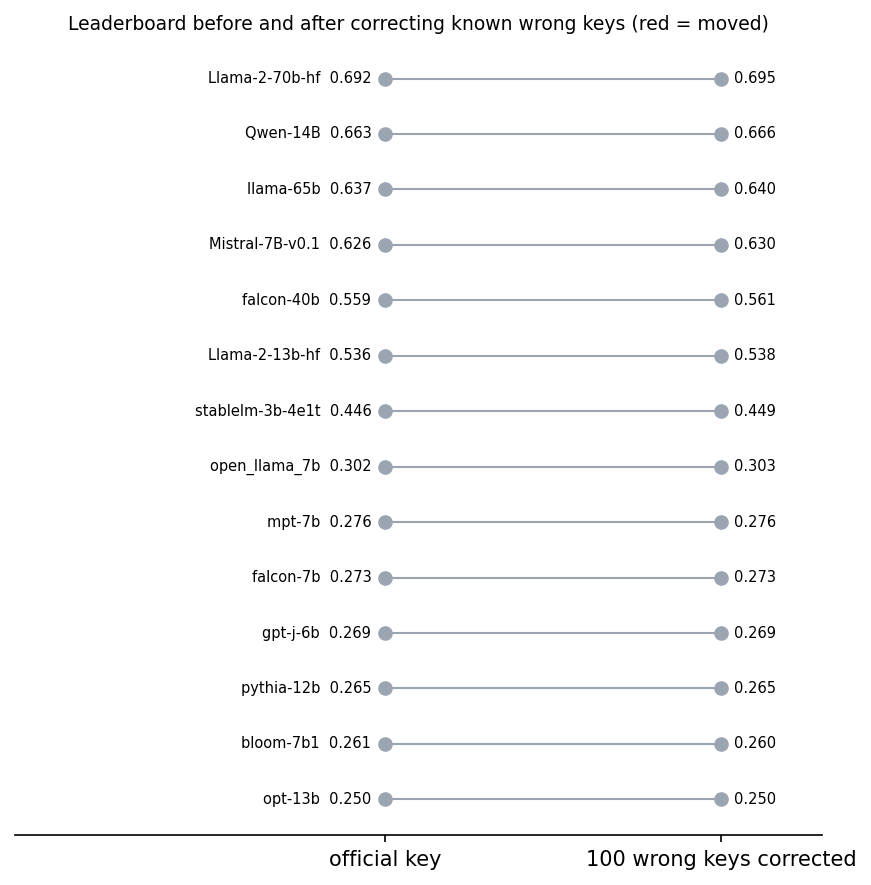

In [ ]:
r_old = (-model_acc).argsort().argsort() + 1
r_new = (-acc_fixed).argsort().argsort() + 1
fig, ax = plt.subplots(figsize=(6, 6), dpi=150)
for i, n in enumerate(names):
    moved = r_old[i] != r_new[i]
    ax.plot([0, 1], [r_old[i], r_new[i]], color="#e45756" if moved else "#9aa5b1",
            lw=2 if moved else 1, marker="o")
    ax.text(-0.04, r_old[i], f"{n.split('__')[-1]}  {model_acc[i]:.3f}", ha="right", va="center", fontsize=7)
    ax.text(1.04, r_new[i], f"{acc_fixed[i]:.3f}", ha="left", va="center", fontsize=7)
ax.set_xlim(-1.1, 1.3); ax.invert_yaxis(); ax.set_xticks([0, 1])
ax.set_xticklabels(["official key", f"{len(fix)} wrong keys corrected"]); ax.set_yticks([])
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.set_title("Leaderboard before and after correcting known wrong keys (red = moved)", fontsize=9)
fig.tight_layout(); fig.savefig("leaderboard_preview.png"); plt.show()

## 14. Export JSON for the D3 tool

In [ ]:
r3 = lambda x: round(float(x), 3)
votes_top = np.stack([(choice[top] == k).sum(0) for k in range(4)], 1)
qjson = [{
    "id": j, "subject": keys[j][0], "row": int(keys[j][1]), "q": qtext[j], "gold": int(gold[j]),
    "conf": r3(conf[j]), "var": r3(var[j]), "acc": r3(acc_q[j]), "top_conf": r3(top_conf[j]),
    "align": r3(align[j]), "entropy": r3(entropy[j]), "irt_a": r3(irt_a[j]), "irt_b": r3(irt_b[j]),
    "cons_alt": int(cons_alt[j]), "cons_share": r3(cons_share[j]),
    "votes_all": [int(x) for x in votes[j]], "votes_top": [int(x) for x in votes_top[j]],
    "redux": labels[j][0] if labels[j] else None,
    "redux_fix": letter_to_idx(labels[j][1]) if labels[j] else None,
} for j in range(Q)]
mjson = [{"name": n, "acc": r3(model_acc[i]), "rank": int(r_old[i]), "theta": r3(theta[i]),
          "top_tier": bool(i in set(top))} for i, n in enumerate(names)]
json.dump(qjson, open("questions.json", "w"))
json.dump(mjson, open("models.json", "w"), indent=1)
np.savez_compressed("matrices.npz", correct=correct, choice=choice.astype(np.int8),
                    p_gold=pg.astype(np.float32), names=np.array(names))
print("saved questions.json, models.json, matrices.npz, leaderboard_preview.png")
print("questions.json size (MB):", round(os.path.getsize("questions.json") / 1e6, 1))

saved questions.json, models.json, matrices.npz, leaderboard_preview.png
questions.json size (MB): 6.6


## 15. SUMMARY 2

In [ ]:
print("===== SUMMARY 2 =====")
print(f"Redux matched: {matched}/{n_red_rows} ({matched/n_red_rows:.1%}); exact {n_exact}, fuzzy {matched - n_exact}")
print(ap.to_string(index=False))
print("IRT ability vs accuracy corr:", round(np.corrcoef(theta, model_acc)[0, 1], 3))
print("corr(conf, var):", round(np.corrcoef(conf, var)[0, 1], 3),
      "| corr(conf, IRT difficulty):", round(np.corrcoef(conf, irt_b)[0, 1], 3))
print(rq3.to_string(index=False))
moved = [(names[i].split("__")[-1], int(r_old[i]), int(r_new[i])) for i in range(M) if r_old[i] != r_new[i]]
print("rank changes after correcting wrong keys:", moved if moved else "none")

===== SUMMARY 2 =====
Redux matched: 5505/5700 (96.6%); exact 5500, fuzzy 5
                     score  AUPRC any error  AUPRC wrong key
                    random            0.074            0.023
      majority vote vs key            0.100            0.052
              low accuracy            0.102            0.055
    IRT low discrimination            0.108            0.061
            IRT difficulty            0.131            0.070
            low confidence            0.169            0.174
negative ability alignment            0.196            0.217
   low top-tier confidence            0.209            0.260
IRT ability vs accuracy corr: 0.995
corr(conf, var): 0.908 | corr(conf, IRT difficulty): -0.703
                      action  questions  pair swaps  Kendall tau  matched-null mean swaps  p (matched)  plain-random mean swaps
         remove Redux-flawed        361           0          1.0                      0.0          1.0                      0.0
    remove our top 361 